--- FOL Resolution Prover ---
Enter formulas in NLTK FOL format (e.g., 'all x. (man(x) -> mortal(x))', 'man(socrates)')
Enter an empty line to finish entering premises.

Enter a premise: all x. (food(x) -> likes(John, x))
Enter a premise: all x. all y. ((eats(x, y) & -killed(x)) -> food(y))
Enter a premise: eats(Anil, Peanuts) & alive(Anil)
Enter a premise: all x. (alive(x) -> -killed(x))
Enter a premise: 

Enter the query/goal to prove (e.g., 'mortal(socrates)'): likes(John, Peanuts)

--- Running FOL Resolution ---
[ 1] {-likes(John,Peanuts)}                        A 
[ 2] {-food(z4), likes(John,z4)}                   A 
[ 3] {-eats(z8,z7), killed(z8), food(z7)}          A 
[ 4] {eats(Anil,Peanuts)}                          A 
[ 5] {alive(Anil)}                                 A 
[ 6] {-alive(z10), -killed(z10)}                   A 
[ 7] {-food(Peanuts)}                              (1, 2) 
[ 8] {-eats(z8,z7), killed(z8), likes(John,z7)}    (2, 3) 
[ 9] {-eats(z8,Peanuts), killed(z8)}

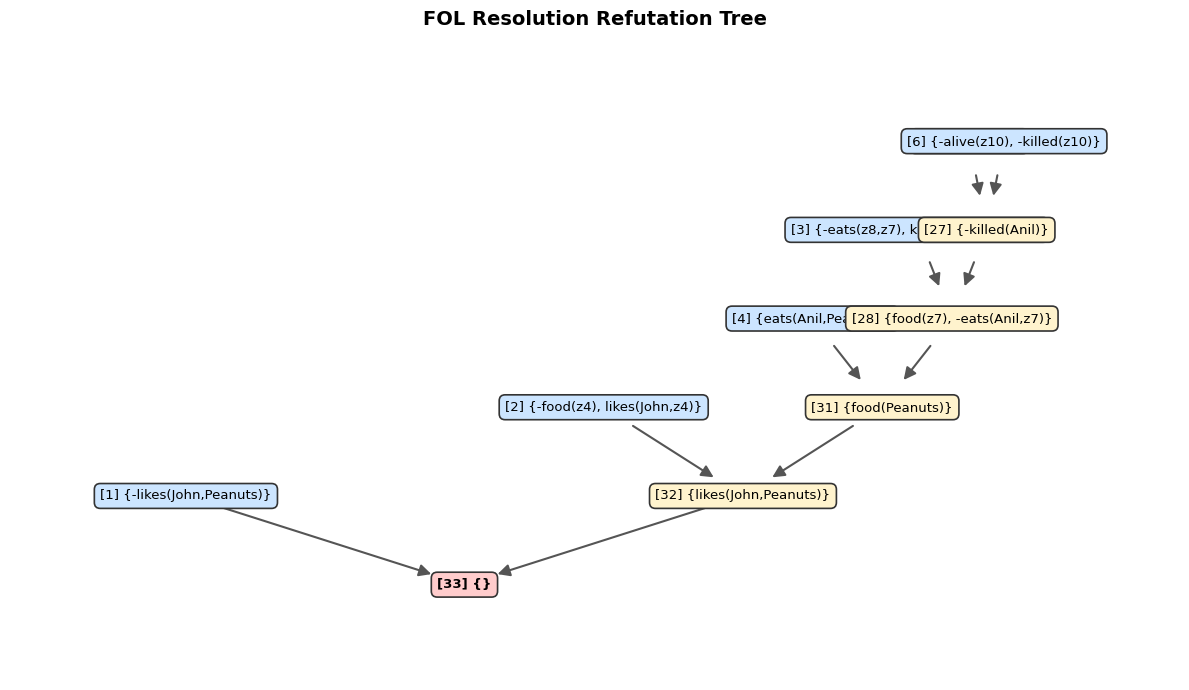

In [5]:
import re
import io
import contextlib
import matplotlib.pyplot as plt
import networkx as nx
from nltk.sem import Expression
from nltk.inference import ResolutionProver

def get_user_input():
    print("--- FOL Resolution Prover ---")
    print("Enter formulas in NLTK FOL format (e.g., 'all x. (man(x) -> mortal(x))', 'man(socrates)')")
    print("Enter an empty line to finish entering premises.\n")

    read_expr = Expression.fromstring
    premises = []

    while True:
        user_in = input("Enter a premise: ").strip()
        if not user_in:
            break
        try:
            expr = read_expr(user_in)
            premises.append(expr)
        except Exception as e:
            print(f"Error parsing expression: {e}. Please try again.")

    while True:
        query_in = input("\nEnter the query/goal to prove (e.g., 'mortal(socrates)'): ").strip()
        if query_in:
            try:
                query = read_expr(query_in)
                break
            except Exception as e:
                print(f"Error parsing query: {e}. Please try again.")

    return premises, query

def parse_proof_steps(verbose_output):
    """Parses NLTK's verbose resolution output into a dictionary of steps."""
    steps = {}
    pattern = re.compile(r'\[\s*(\d+)\]\s+(\{.*?\})\s+(A|\(\d+,\s*\d+\))')
    for line in verbose_output.splitlines():
        match = pattern.search(line)
        if match:
            step_id = int(match.group(1))
            clause = match.group(2)
            source = match.group(3)
            if source == 'A':
                parents = []
            else:
                parents = [int(p.strip()) for p in source.strip('()').split(',')]
            steps[step_id] = {'clause': clause, 'parents': parents}
    return steps

def build_tree_positions(G, root, width=1.0, vert_gap=0.25, vert_loc=0, xcenter=0.5, pos=None):
    """Computes clean hierarchical positions for the proof tree."""
    if pos is None:
        pos = {root: (xcenter, vert_loc)}
    else:
        pos[root] = (xcenter, vert_loc)
    children = list(G.predecessors(root))
    if children:
        dx = width / len(children)
        nextx = xcenter - width / 2 - dx / 2
        for child in children:
            nextx += dx
            pos = build_tree_positions(G, child, width=dx, vert_gap=vert_gap,
                                       vert_loc=vert_loc - vert_gap, xcenter=nextx, pos=pos)
    return pos

def draw_resolution_tree(steps):
    """Builds and plots the pruned resolution refutation tree."""
    empty_steps = [k for k, v in steps.items() if v['clause'] == '{}']
    if not empty_steps:
        print("No empty clause {} found to plot a refutation tree.")
        return

    # FIXED: Extracting the actual root step instead of using the list object
    root = empty_steps[0]
    G = nx.DiGraph()

    # Trace backwards from {} to keep only the steps used in the proof
    queue = [root]
    visited = set()
    while queue:
        curr = queue.pop(0)
        if curr in visited:
            continue
        visited.add(curr)
        label = f"[{curr}] {steps[curr]['clause']}"
        G.add_node(curr, label=label)
        for p in steps[curr]['parents']:
            G.add_edge(p, curr)
            queue.append(p)

    pos = build_tree_positions(G, root, width=2.5, vert_gap=0.35, vert_loc=0)
    pos = {node: (x, -y) for node, (x, y) in pos.items()}

    plt.figure(figsize=(12, 7))
    labels = nx.get_node_attributes(G, 'label')

    node_colors = []
    for node in G.nodes():
        if node == root:
            node_colors.append('#ffcccc')   # Empty clause {} (Red)
        elif len(steps[node]['parents']) == 0:
            node_colors.append('#cce5ff')   # Initial premises/axioms (Blue)
        else:
            node_colors.append('#fff3cd')   # Derived resolvents (Yellow)

    nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle='-|>', arrowsize=18,
                           edge_color='#555555', width=1.5, node_size=2500)

    for node, (x, y) in pos.items():
        plt.text(x, y, labels[node], ha='center', va='center', fontsize=9.5,
                 fontweight='bold' if node == root else 'normal',
                 bbox=dict(boxstyle='round,pad=0.45', facecolor=node_colors[list(G.nodes()).index(node)],
                           edgecolor='#333333', lw=1.2))

    plt.title("FOL Resolution Refutation Tree", fontsize=14, fontweight='bold', pad=15)
    plt.axis('off')
    plt.margins(0.15)
    plt.tight_layout()
    plt.show()

def main():
    premises, query = get_user_input()

    # Capture NLTK verbose output
    prover = ResolutionProver()
    buffer = io.StringIO()
    with contextlib.redirect_stdout(buffer):
        result = prover.prove(query, premises, verbose=True)
    verbose_text = buffer.getvalue()

    print("\n--- Running FOL Resolution ---")
    print(verbose_text)
    print(f"Result: The query is {'PROVED (True)' if result else 'NOT PROVED (False)'}\n")

    if result:
        steps = parse_proof_steps(verbose_text)
        draw_resolution_tree(steps)

if __name__ == "__main__":
    main()